# Tugas Praktikum 6: Clustering (Advance)
**Nama:** Muhamad Nafi Mulyo  
**NRP:** 5054251005  
**Mata Kuliah:** Data Mining

Praktikum ini menerapkan empat algoritma clustering lanjutan (Agglomerative, DBSCAN, GMM, Spectral) pada dataset **Palmer Penguins**, lalu membandingkannya dengan Silhouette Score, Rand Index, NMI, dan uji kestabilan.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, rand_score, normalized_mutual_info_score

import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
pd.set_option("display.width", 120)

## 1. Unduh dan Import Dataset

In [2]:
URL = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"
df = pd.read_csv(URL)
display(df.head())
print("shape:", df.shape)
df.info()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


shape: (344, 8)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


## 2. Eksplorasi dan Pembersihan Data

In [3]:
FEATURES = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
print("Jumlah nilai kosong per kolom:")
df.isna().sum()

Jumlah nilai kosong per kolom:


species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

In [4]:
n_before = len(df)
df_clean = df.dropna(subset=FEATURES + ["species"]).reset_index(drop=True)
n_after = len(df_clean)
print(f"Baris sebelum pembersihan : {n_before}")
print(f"Baris sesudah pembersihan : {n_after}  (dibuang {n_before - n_after})")
print("\nJumlah data per spesies (setelah pembersihan):")
print(df_clean["species"].value_counts())
print("\nJumlah data per spesies (sebelum pembersihan):")
print(df["species"].value_counts())

Baris sebelum pembersihan : 344
Baris sesudah pembersihan : 342  (dibuang 2)

Jumlah data per spesies (setelah pembersihan):
species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64

Jumlah data per spesies (sebelum pembersihan):
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


In [5]:
df_clean[FEATURES].describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


**Catatan skala:** `body_mass_g` berada pada kisaran ribuan (gram), sedangkan `bill_depth_mm` hanya belasan (milimeter). Tanpa standardisasi, fitur dengan skala besar akan mendominasi perhitungan jarak, sehingga standardisasi wajib dilakukan.

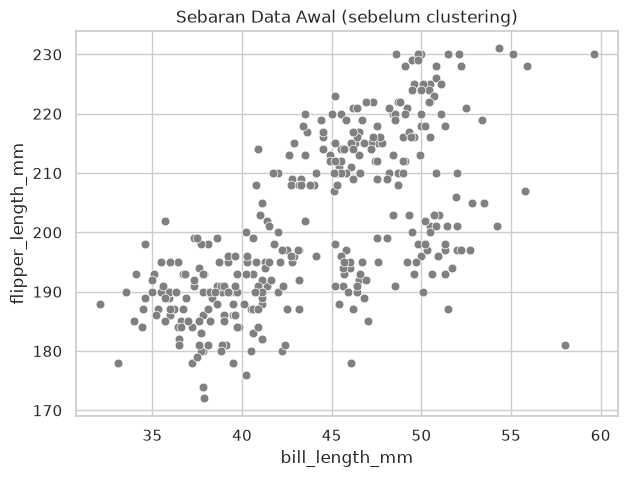

In [6]:
palette = {"Adelie": "tab:orange", "Chinstrap": "tab:purple", "Gentoo": "tab:cyan"}
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_clean, x="bill_length_mm", y="flipper_length_mm", color="gray", s=40)
plt.title("Sebaran Data Awal (sebelum clustering)")
plt.show()

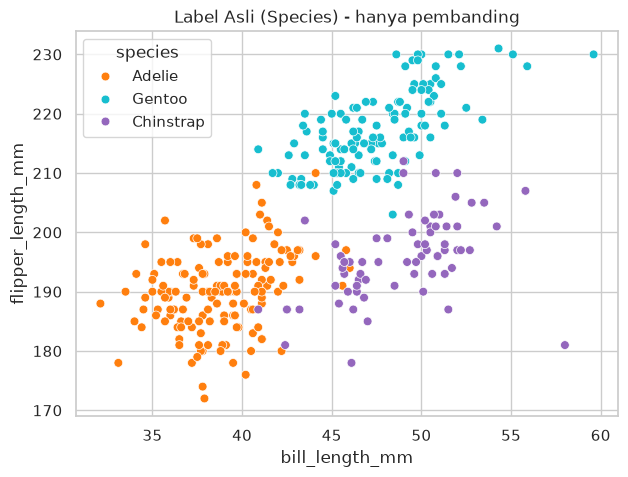

In [7]:
# Hanya untuk referensi visual: sebaran dengan warna spesies (label asli, TIDAK dipakai clustering)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_clean, x="bill_length_mm", y="flipper_length_mm", hue="species", palette=palette, s=40)
plt.title("Label Asli (Species) - hanya pembanding")
plt.show()

## 3. Standardisasi Data

In [8]:
X = df_clean[FEATURES].values
y = df_clean["species"].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("X:", X.shape, "| y:", y.shape)
pd.DataFrame(X_scaled, columns=FEATURES).describe().round(3)

X: (342, 4) | y: (342,)


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000,342.000,342.000,342.000
mean,0.000,0.000,-0.000,0.000
std,1.001,1.001,1.001,1.001
min,-2.169,-2.054,-2.059,-1.875
25%,-0.862,-0.787,-0.777,-0.814
50%,0.097,0.075,-0.279,-0.190
75%,0.840,0.785,0.861,0.685
max,2.876,2.205,2.143,2.620


In [9]:
df_std = pd.DataFrame(X_scaled, columns=FEATURES)
df_std["species"] = y
df_std.head()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,species
0,-0.884499,0.785449,-1.418347,-0.564142,Adelie
1,-0.811126,0.126188,-1.062250,-0.501703,Adelie
2,-0.664380,0.430462,-0.421277,-1.188532,Adelie
3,-1.324737,1.089724,-0.563715,-0.938776,Adelie
4,-0.847812,1.748985,-0.777373,-0.689020,Adelie


## 4. Penerapan Algoritma

### 4.1 Agglomerative Clustering
Menggunakan **linkage Ward** (meminimalkan kenaikan variansi dalam kluster, jarak Euclidean), jumlah kluster = 3.

Ukuran kluster: {np.int64(0): np.int64(162), np.int64(1): np.int64(123), np.int64(2): np.int64(57)}


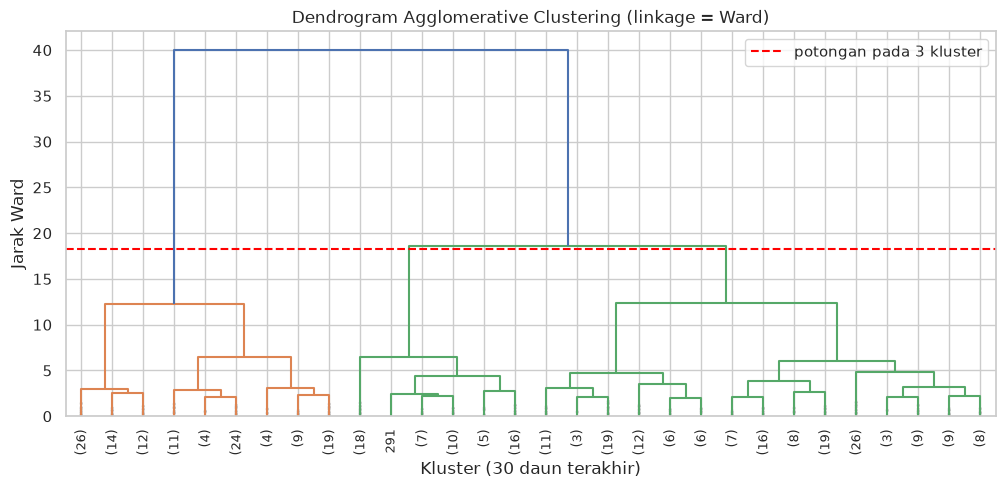

In [10]:
agg = AgglomerativeClustering(n_clusters=3, linkage="ward")
labels_agg = agg.fit_predict(X_scaled)
print("Ukuran kluster:", dict(zip(*np.unique(labels_agg, return_counts=True))))

Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True)
cut = Z[-2, 2]
plt.axhline(cut * 0.98, color="red", ls="--", label="potongan pada 3 kluster")
plt.title("Dendrogram Agglomerative Clustering (linkage = Ward)")
plt.xlabel("Kluster (30 daun terakhir)"); plt.ylabel("Jarak Ward")
plt.legend(); plt.show()

### 4.2 DBSCAN
Dimulai dari `eps=0.5`, `MinPts=5`, kemudian dicoba beberapa nilai `eps` lain.

In [11]:
rows = []
for eps in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0, 1.2]:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X_scaled)
    rows.append({"eps": eps, "MinPts": 5,
                 "jumlah_kluster": len(set(lab)) - (1 if -1 in lab else 0),
                 "jumlah_noise": int((lab == -1).sum()),
                 "persen_noise": round((lab == -1).mean() * 100, 1)})
dbscan_sweep = pd.DataFrame(rows)
dbscan_sweep

,eps,MinPts,jumlah_kluster,jumlah_noise,persen_noise
0,0.3,5,4,317,92.7
1,0.4,5,10,171,50.0
2,0.5,5,4,69,20.2
3,0.6,5,2,33,9.6
4,0.7,5,2,16,4.7
5,0.8,5,2,5,1.5
6,1.0,5,2,1,0.3
7,1.2,5,2,1,0.3


In [12]:
EPS_MAIN = 0.5   # nilai awal dari soal; dipakai untuk perbandingan utama
labels_db = DBSCAN(eps=EPS_MAIN, min_samples=5).fit_predict(X_scaled)
print(f"DBSCAN eps={EPS_MAIN}: {len(set(labels_db)) - 1} kluster, {(labels_db == -1).sum()} titik noise")
print("Ukuran kluster:", dict(zip(*np.unique(labels_db, return_counts=True))))

DBSCAN eps=0.5: 4 kluster, 69 titik noise
Ukuran kluster: {np.int64(-1): np.int64(69), np.int64(0): np.int64(118), np.int64(1): np.int64(113), np.int64(2): np.int64(15), np.int64(3): np.int64(27)}


### 4.3 Gaussian Mixture Models (GMM)
3 komponen.

In [13]:
gmm = GaussianMixture(n_components=3, random_state=SEED, n_init=5)
labels_gmm = gmm.fit_predict(X_scaled)
print("Ukuran kluster:", dict(zip(*np.unique(labels_gmm, return_counts=True))))

Ukuran kluster: {np.int64(0): np.int64(123), np.int64(1): np.int64(152), np.int64(2): np.int64(67)}


### 4.4 Spectral Clustering
3 kluster, affinity `nearest_neighbors`.

In [14]:
spec = SpectralClustering(n_clusters=3, affinity="nearest_neighbors", n_neighbors=10,
                          assign_labels="kmeans", random_state=SEED)
labels_spec = spec.fit_predict(X_scaled)
print("Ukuran kluster:", dict(zip(*np.unique(labels_spec, return_counts=True))))

Ukuran kluster: {np.int32(0): np.int64(162), np.int32(1): np.int64(123), np.int32(2): np.int64(57)}


### 4.5 Visualisasi Hasil Clustering

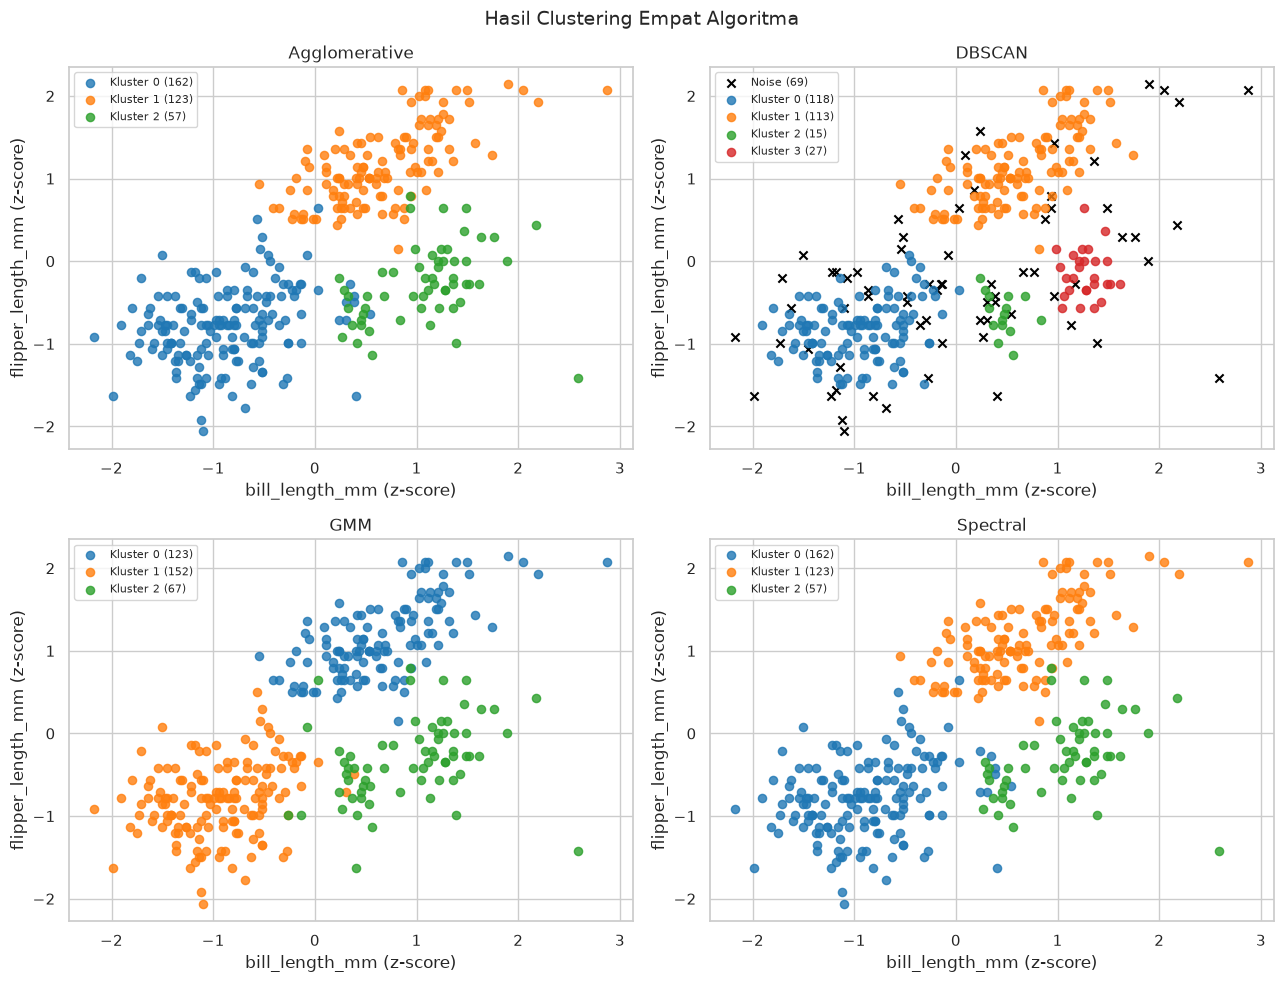

In [15]:
results = {"Agglomerative": labels_agg, "DBSCAN": labels_db, "GMM": labels_gmm, "Spectral": labels_spec}
cols = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown", "tab:pink", "tab:olive"]
fi, fj = FEATURES.index("bill_length_mm"), FEATURES.index("flipper_length_mm")

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (name, lab) in zip(axes.ravel(), results.items()):
    for k in sorted(set(lab)):
        m = lab == k
        if k == -1:
            ax.scatter(X_scaled[m, fi], X_scaled[m, fj], c="black", marker="x", s=35, label=f"Noise ({m.sum()})")
        else:
            ax.scatter(X_scaled[m, fi], X_scaled[m, fj], c=cols[k % len(cols)], s=35, alpha=.8, label=f"Kluster {k} ({m.sum()})")
    ax.set_title(name); ax.set_xlabel("bill_length_mm (z-score)"); ax.set_ylabel("flipper_length_mm (z-score)")
    ax.legend(fontsize=8)
plt.suptitle("Hasil Clustering Empat Algoritma", fontsize=14)
plt.tight_layout(); plt.show()

## 5. Evaluasi Hasil Clustering

### 5.1 Silhouette Score (internal), Rand Index dan NMI (eksternal terhadap `species`)

In [16]:
def sil(X, lab):
    m = lab != -1
    if len(set(lab[m])) < 2: return np.nan, int((~m).sum())
    return silhouette_score(X[m], lab[m]), int((~m).sum())

rows = []
for name, lab in results.items():
    s, dropped = sil(X_scaled, lab)
    rows.append({"Algoritma": name, "Silhouette": s, "Titik dibuang (noise)": dropped,
                 "Rand Index": rand_score(y, lab), "NMI": normalized_mutual_info_score(y, lab)})
eval_df = pd.DataFrame(rows).set_index("Algoritma")
eval_df.round(4)

,Silhouette,Titik dibuang (noise),Rand Index,NMI
Algoritma,,,,
Agglomerative,0.4541,0,0.9608,0.9007
DBSCAN,0.4235,69,0.8525,0.6631
GMM,0.4545,0,0.9817,0.9349
Spectral,0.4550,0,0.9608,0.9007


In [17]:
print(f"Silhouette DBSCAN dihitung tanpa {eval_df.loc['DBSCAN','Titik dibuang (noise)']} titik noise dari {len(X_scaled)} titik.")
for name, lab in results.items():
    print(f"\n== {name}: tabel silang kluster vs species ==")
    print(pd.crosstab(lab, y, rownames=["kluster"], colnames=["species"]))

Silhouette DBSCAN dihitung tanpa 69 titik noise dari 342 titik.

== Agglomerative: tabel silang kluster vs species ==
species  Adelie  Chinstrap  Gentoo
kluster                           
0           151         11       0
1             0          0     123
2             0         57       0

== DBSCAN: tabel silang kluster vs species ==
species  Adelie  Chinstrap  Gentoo
kluster                           
-1           36         23      10
 0          115          3       0
 1            0          0     113
 2            0         15       0
 3            0         27       0

== GMM: tabel silang kluster vs species ==
species  Adelie  Chinstrap  Gentoo
kluster                           
0             0          0     123
1           149          3       0
2             2         65       0

== Spectral: tabel silang kluster vs species ==
species  Adelie  Chinstrap  Gentoo
kluster                           
0           151         11       0
1             0          0     123
2      

### 5.2 Uji Kestabilan
Tiap algoritma dijalankan ulang pada **90% data acak** sebanyak **3 kali**. Label hasil subsampel dibandingkan dengan label hasil data penuh pada titik-titik yang sama menggunakan **Rand Index** dan **NMI** (keduanya invarian terhadap permutasi nomor kluster). Pada DBSCAN, noise (-1) diperlakukan sebagai satu label tersendiri.

In [18]:
makers = {
    "Agglomerative": lambda: AgglomerativeClustering(n_clusters=3, linkage="ward"),
    "DBSCAN":        lambda: DBSCAN(eps=EPS_MAIN, min_samples=5),
    "GMM":           lambda: GaussianMixture(n_components=3, random_state=SEED, n_init=5),
    "Spectral":      lambda: SpectralClustering(n_clusters=3, affinity="nearest_neighbors", n_neighbors=10,
                                                assign_labels="kmeans", random_state=SEED),
}
rng = np.random.RandomState(SEED)
n = len(X_scaled); n_sub = int(0.9 * n)
subsets = [rng.choice(n, n_sub, replace=False) for _ in range(3)]

stab_rows = []
for name, mk in makers.items():
    for r, idx in enumerate(subsets, 1):
        lab_sub = mk().fit_predict(X_scaled[idx])
        ref = results[name][idx]
        stab_rows.append({"Algoritma": name, "Run": r, "Rand vs penuh": rand_score(ref, lab_sub),
                          "NMI vs penuh": normalized_mutual_info_score(ref, lab_sub),
                          "Jumlah kluster": len(set(lab_sub)) - (1 if -1 in lab_sub else 0),
                          "Noise": int((lab_sub == -1).sum())})
stab_df = pd.DataFrame(stab_rows)
stab_df.round(4)

,Algoritma,Run,Rand vs penuh,NMI vs penuh,Jumlah kluster,Noise
0,Agglomerative,1,0.8364,0.7410,3,0
1,Agglomerative,2,0.8641,0.7683,3,0
2,Agglomerative,3,0.9680,0.9144,3,0
3,DBSCAN,1,0.9686,0.9063,4,71
4,DBSCAN,2,0.9819,0.9390,4,64
5,DBSCAN,3,0.9539,0.9014,4,75
6,GMM,1,1.0000,1.0000,3,0
7,GMM,2,1.0000,1.0000,3,0
8,GMM,3,1.0000,1.0000,3,0
9,Spectral,1,0.9958,0.9826,3,0


In [19]:
stab_sum = stab_df.groupby("Algoritma")[["Rand vs penuh", "NMI vs penuh"]].agg(["mean", "std"])
stab_sum.columns = ["Rand mean", "Rand std", "NMI mean", "NMI std"]
stab_sum.round(4)

,Rand mean,Rand std,NMI mean,NMI std
Algoritma,,,,
Agglomerative,0.8895,0.0694,0.8079,0.0932
DBSCAN,0.9681,0.0140,0.9156,0.0204
GMM,1.0000,0.0000,1.0000,0.0000
Spectral,0.9972,0.0024,0.9884,0.0101


### 5.3 Tabel Perbandingan

In [20]:
summary = eval_df.join(stab_sum[["Rand mean", "NMI mean"]].rename(
    columns={"Rand mean": "Stabilitas Rand (rata-rata)", "NMI mean": "Stabilitas NMI (rata-rata)"}))
summary.round(4)

,Silhouette,Titik dibuang (noise),Rand Index,NMI,Stabilitas Rand (rata-rata),Stabilitas NMI (rata-rata)
Algoritma,,,,,,
Agglomerative,0.4541,0,0.9608,0.9007,0.8895,0.8079
DBSCAN,0.4235,69,0.8525,0.6631,0.9681,0.9156
GMM,0.4545,0,0.9817,0.9349,1.0000,1.0000
Spectral,0.4550,0,0.9608,0.9007,0.9972,0.9884


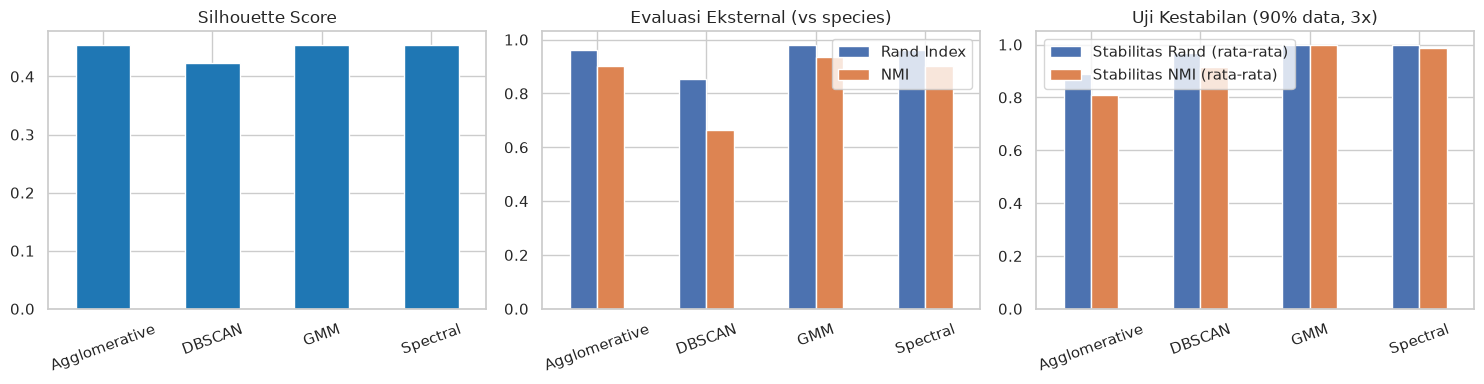

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
summary[["Silhouette"]].plot.bar(ax=axes[0], legend=False, color="tab:blue", rot=20); axes[0].set_title("Silhouette Score")
summary[["Rand Index", "NMI"]].plot.bar(ax=axes[1], rot=20); axes[1].set_title("Evaluasi Eksternal (vs species)")
summary[["Stabilitas Rand (rata-rata)", "Stabilitas NMI (rata-rata)"]].plot.bar(ax=axes[2], rot=20); axes[2].set_title("Uji Kestabilan (90% data, 3x)")
for a in axes: a.set_xlabel("")
plt.tight_layout(); plt.show()

## 6. Laporan dan Kesimpulan

### 6.1 Hasil eksplorasi dan pembersihan data
- Dataset Palmer Penguins berisi **344 baris**. Sebanyak **2 baris** memiliki nilai kosong pada keempat kolom numerik, sehingga tersisa **342 baris** setelah pembersihan (Adelie 151, Gentoo 123, Chinstrap 68).
- Kolom `sex` memiliki 11 nilai kosong, tetapi tidak dipakai sebagai fitur sehingga tidak ikut dibersihkan.
- Skala antar fitur sangat berbeda (`body_mass_g` rata-rata ~4200 gram, `bill_depth_mm` rata-rata ~17 mm), sehingga data distandardisasi dengan z-score (rata-rata 0, std 1) sebelum clustering. Kolom `species` hanya dipakai sebagai pembanding.

### 6.2 Visualisasi dan nilai evaluasi keempat algoritma
| Algoritma | Silhouette | Rand Index | NMI | Stabilitas Rand | Stabilitas NMI |
|---|---|---|---|---|---|
| Agglomerative (Ward) | 0.4541 | 0.9608 | 0.9007 | 0.8895 | 0.8079 |
| DBSCAN (eps=0.5, MinPts=5) | 0.4235 (69 noise dibuang) | 0.8525 | 0.6631 | 0.9681 | 0.9156 |
| **GMM** | 0.4545 | **0.9817** | **0.9349** | **1.0000** | **1.0000** |
| Spectral | **0.4550** | 0.9608 | 0.9007 | 0.9972 | 0.9884 |

- **Silhouette:** Agglomerative, GMM, dan Spectral hampir identik (~0.454), selisihnya terlalu kecil untuk menentukan pemenang. DBSCAN lebih rendah (0.4235) dan nilainya pun dihitung setelah 69 titik (20%) dibuang sebagai noise.
- **Kecocokan dengan species (Rand Index dan NMI):** GMM paling mendekati label asli. Agglomerative dan Spectral menghasilkan kluster yang sama persis (11 Chinstrap tergabung ke kluster Adelie), sedangkan DBSCAN paling rendah.
- **Kestabilan (90% data, 3 kali):** GMM paling stabil (identik pada ketiga percobaan), disusul Spectral. **Agglomerative paling tidak stabil** (rata-rata Rand 0.8895, terendah 0.8364), karena penggabungan kluster pada hierarchical clustering bersifat greedy dan tidak dapat dibatalkan, sehingga membuang sebagian titik dapat mengubah hasil pemotongan 3 kluster.
- **DBSCAN sulit disetel pada data ini.** Pada eps=0.5 menghasilkan 4 kluster dengan 69 noise; pada eps yang lebih besar (0.6 ke atas) hanya 2 kluster karena Adelie dan Chinstrap menyatu; pada eps yang lebih kecil sebagian besar titik menjadi noise. Tidak ada nilai eps yang menghasilkan 3 spesies, karena Adelie dan Chinstrap saling tumpang-tindih sehingga satu nilai eps tidak cukup memisahkannya.

### 6.3 Kesimpulan
**Algoritma yang paling cocok untuk dataset ini adalah GMM**, dengan alasan:
1. **Paling cocok dengan species:** Rand Index (0.982) dan NMI (0.935) tertinggi di antara keempatnya.
2. **Paling stabil:** hasilnya tidak berubah sama sekali ketika 10% data dibuang secara acak.
3. **Sesuai bentuk data:** tiap spesies membentuk kelompok yang kira-kira berbentuk lonjong (distribusi Gaussian) dengan ukuran berbeda, dan itu persis asumsi GMM.
4. **Tidak ada biaya tambahan yang berarti:** pada 342 baris dengan 4 fitur, GMM sama mudahnya dijalankan seperti algoritma lain.

**Pertimbangan kesederhanaan.** Jika dua algoritma memberi hasil serupa, algoritma yang lebih sederhana sebaiknya dipilih. Agglomerative memang sederhana dan menghasilkan Silhouette serta kluster yang hampir sama dengan Spectral dan GMM, tetapi **paling tidak stabil**, sehingga kesederhanaannya tidak sebanding dengan risikonya. Spectral Clustering menjadi alternatif yang baik (stabil dan mendekati GMM), namun lebih rumit karena bergantung pada graf tetangga dan parameter `n_neighbors`, tanpa memberi hasil lebih baik dari GMM.

**DBSCAN kurang cocok** karena kepadatan antar spesies tidak jelas terpisah (Adelie dan Chinstrap tumpang-tindih), sehingga banyak titik menjadi noise atau dua spesies tergabung.

**Keterbatasan:** (1) jumlah kluster (3) diberikan oleh soal, sehingga pemilihan jumlah kluster tidak diuji; (2) Silhouette tidak membedakan tiga algoritma teratas; (3) uji kestabilan hanya 3 kali pengulangan, sehingga angkanya bersifat indikatif; (4) label species dipakai sebagai acuan, padahal clustering bersifat tanpa pengawasan dan belum tentu kluster terbaiknya sama dengan species.